# BÀI THỰC HÀNH 3.2: SO SÁNH VÀ ĐÁNH GIÁ MÔ HÌNH PHÂN LOẠI TRÊN TẬP DỮ LIỆU DIGITS (KNN VS LOGISTIC REGRESSION)
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


In [1]:
from sklearn import datasets, linear_model, neighbors

X_digits, y_digits = datasets.load_digits(return_X_y=True)
X_digits = X_digits / X_digits.max()

n_samples = len(X_digits)

X_train = X_digits[: int(0.9 * n_samples)]
y_train = y_digits[: int(0.9 * n_samples)]
X_test = X_digits[int(0.9 * n_samples) :]
y_test = y_digits[int(0.9 * n_samples) :]

knn = neighbors.KNeighborsClassifier()
logistic = linear_model.LogisticRegression(max_iter=1000)

print("KNN score: %f" % knn.fit(X_train, y_train).score(X_test, y_test))
print(
    "LogisticRegression score: %f"
    % logistic.fit(X_train, y_train).score(X_test, y_test)
)


KNN score: 0.961111
LogisticRegression score: 0.933333


## 1. Mở rộng đánh giá chi tiết: Dự đoán nhãn kiểm thử và Báo cáo phân loại (Classification Report)


In [2]:
# ==============================================================================
# BƯỚC 1: DỰ ĐOÁN NHÃN VÀ ĐÁNH GIÁ CHI TIẾT HIỆU NĂNG CỦA HAI MÔ HÌNH
# ==============================================================================

# Import thư viện vẽ đồ thị và các hàm đo lường hiệu năng từ scikit-learn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# Thực hiện dự đoán nhãn các chữ số trên tập kiểm thử (X_test) bằng mô hình K-NN đã huấn luyện
y_pred_knn = knn.predict(X_test)

# Thực hiện dự đoán nhãn các chữ số trên tập kiểm thử (X_test) bằng mô hình Logistic Regression đã huấn luyện
y_pred_logistic = logistic.predict(X_test)

# Tính toán độ chính xác tổng quát (Accuracy) của từng mô hình trên tập Test
acc_knn = accuracy_score(y_test, y_pred_knn)  # Tỷ lệ dự đoán đúng của K-NN
acc_log = accuracy_score(y_test, y_pred_logistic)  # Tỷ lệ dự đoán đúng của Logistic Regression

# Tính toán điểm F1-Score dạng Weighted (trung bình có trọng số theo số lượng mẫu của từng chữ số)
f1_weighted_knn = f1_score(y_test, y_pred_knn, average='weighted')
f1_weighted_log = f1_score(y_test, y_pred_logistic, average='weighted')

# Tính toán điểm F1-Score dạng Macro (trung bình cộng đồng đều giữa tất cả 10 chữ số từ 0 đến 9)
f1_macro_knn = f1_score(y_test, y_pred_knn, average='macro')
f1_macro_log = f1_score(y_test, y_pred_logistic, average='macro')

# Tổng hợp các chỉ số so sánh vào một DataFrame để hiển thị dạng bảng
df_summary = pd.DataFrame({
    'Chỉ số đánh giá': [
        'Accuracy',
        'F1-Score (Weighted)',
        'F1-Score (Macro)',
        'Số mẫu dự đoán đúng',
        'Số mẫu dự đoán sai'
    ],
    'Mô hình K-NN': [
        f'{acc_knn * 100:.2f}%',
        f'{f1_weighted_knn * 100:.2f}%',
        f'{f1_macro_knn * 100:.2f}%',
        f'{(y_pred_knn == y_test).sum()}/{len(y_test)}',
        f'{(y_pred_knn != y_test).sum()}/{len(y_test)}'
    ],
    'Mô hình Logistic Regression': [
        f'{acc_log * 100:.2f}%',
        f'{f1_weighted_log * 100:.2f}%',
        f'{f1_macro_log * 100:.2f}%',
        f'{(y_pred_logistic == y_test).sum()}/{len(y_test)}',
        f'{(y_pred_logistic != y_test).sum()}/{len(y_test)}'
    ]
})

# In bảng tổng hợp so sánh hiệu năng
print("=== BẢNG SO SÁNH HIỆU NĂNG TỔNG QUAN GIỮA KNN VÀ LOGISTIC REGRESSION ===")
print(df_summary.to_string(index=False))

# In báo cáo phân loại chi tiết (Precision, Recall, F1-score) cho từng chữ số (0 - 9) của mô hình K-NN
print("\n" + "=" * 60)
print("=== BÁO CÁO PHÂN LOẠI CHI TIẾT - MÔ HÌNH K-NN ===")
print("=" * 60)
print(classification_report(y_test, y_pred_knn, digits=4))

# In báo cáo phân loại chi tiết (Precision, Recall, F1-score) cho từng chữ số (0 - 9) của mô hình Logistic Regression
print("=" * 60)
print("=== BÁO CÁO PHÂN LOẠI CHI TIẾT - LOGISTIC REGRESSION ===")
print("=" * 60)
print(classification_report(y_test, y_pred_logistic, digits=4))


=== BẢNG SO SÁNH HIỆU NĂNG TỔNG QUAN GIỮA KNN VÀ LOGISTIC REGRESSION ===
    Chỉ số đánh giá Mô hình K-NN Mô hình Logistic Regression
           Accuracy       96.11%                      93.33%
F1-Score (Weighted)       96.07%                      93.09%
   F1-Score (Macro)       96.06%                      93.09%
Số mẫu dự đoán đúng      173/180                     168/180
 Số mẫu dự đoán sai        7/180                      12/180

=== BÁO CÁO PHÂN LOẠI CHI TIẾT - MÔ HÌNH K-NN ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        16
           1     0.9500    1.0000    0.9744        19
           2     0.9444    1.0000    0.9714        17
           3     0.9412    0.8889    0.9143        18
           4     1.0000    0.9500    0.9744        20
           5     0.9000    1.0000    0.9474        18
           6     1.0000    1.0000    1.0000        18
           7     0.9500    1.0000    0.9744        19
           8     0.9375

## 2. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) lần lượt cho cả 2 mô hình


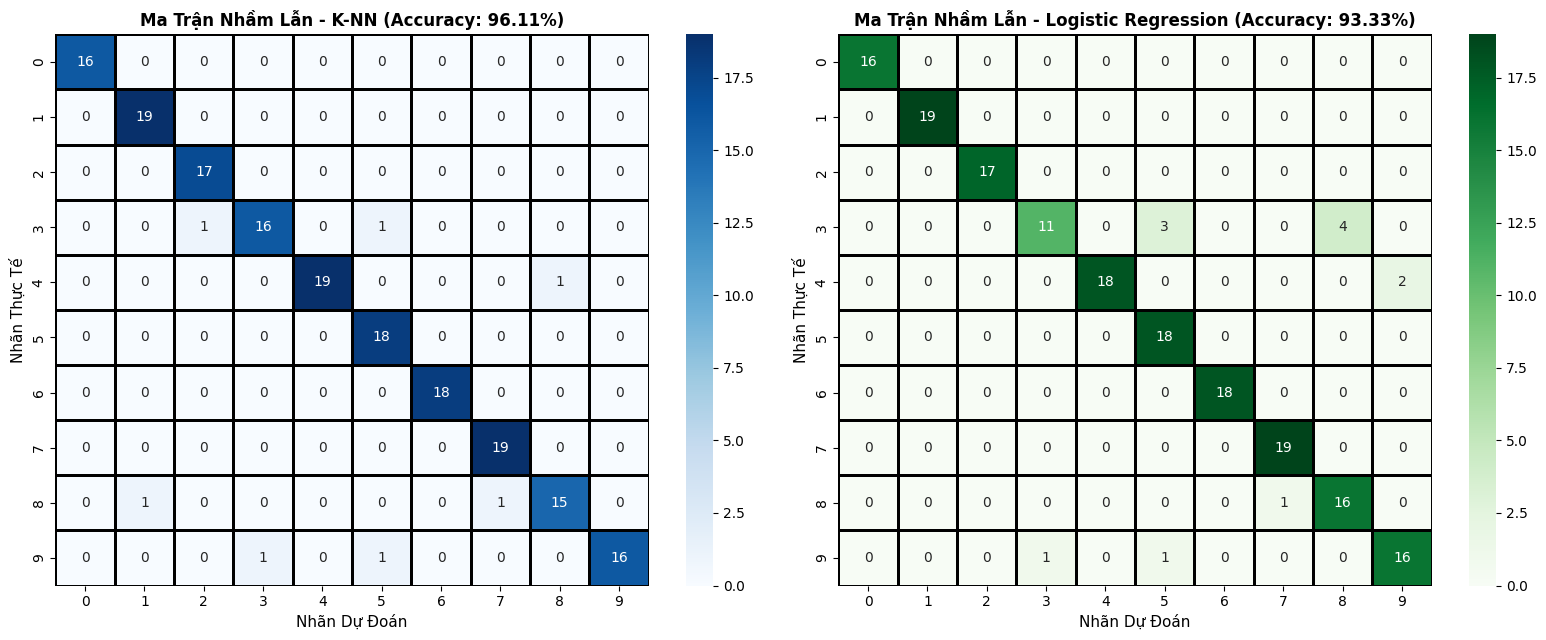

In [3]:
# ==============================================================================
# BƯỚC 2: TÍNH TOÁN VÀ VẼ MA TRẬN NHẦM LẪN (CONFUSION MATRIX) CHO 2 MÔ HÌNH
# ==============================================================================

# Tính ma trận nhầm lẫn 10x10 cho mô hình K-NN
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Tính ma trận nhầm lẫn 10x10 cho mô hình Logistic Regression
cm_log = confusion_matrix(y_test, y_pred_logistic)

# Khởi tạo khung hình chứa 2 biểu đồ ma trận cạnh nhau (1 hàng, 2 cột)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6.5))

# ------------------------------------------------------------------------------
# 2.1. Vẽ ma trận nhầm lẫn của mô hình K-NN (sử dụng tông màu xanh lam - Blues)
# ------------------------------------------------------------------------------
sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True,
    linewidths=1,
    linecolor='black',
    ax=axes[0]
)
axes[0].set_title(f"Ma Trận Nhầm Lẫn - K-NN (Accuracy: {acc_knn * 100:.2f}%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Nhãn Dự Đoán", fontsize=11)
axes[0].set_ylabel("Nhãn Thực Tế", fontsize=11)

# ------------------------------------------------------------------------------
# 2.2. Vẽ ma trận nhầm lẫn của Logistic Regression (sử dụng tông màu xanh lá - Greens)
# ------------------------------------------------------------------------------
sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Greens',
    cbar=True,
    linewidths=1,
    linecolor='black',
    ax=axes[1]
)
axes[1].set_title(f"Ma Trận Nhầm Lẫn - Logistic Regression (Accuracy: {acc_log * 100:.2f}%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Nhãn Dự Đoán", fontsize=11)
axes[1].set_ylabel("Nhãn Thực Tế", fontsize=11)

# Tự động căn chỉnh lề biểu đồ
plt.tight_layout()
plt.show()


## 3. Trực quan hóa các mẫu nhận dạng sai của mô hình này nhưng đúng với mô hình kia (và ngược lại)


Số mẫu KNN đoán sai nhưng Logistic đoán đúng: 1 mẫu (Chỉ số index: [np.int64(173)])
Số mẫu Logistic đoán sai nhưng KNN đoán đúng: 6 mẫu (Chỉ số index: [np.int64(11), np.int64(63), np.int64(73), np.int64(109), np.int64(112), np.int64(113)])


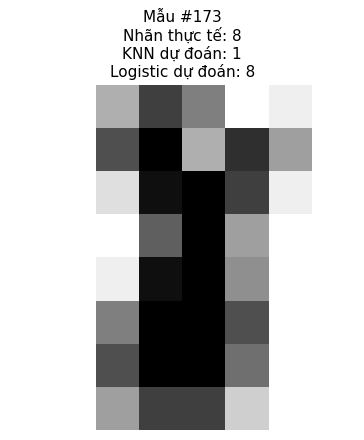

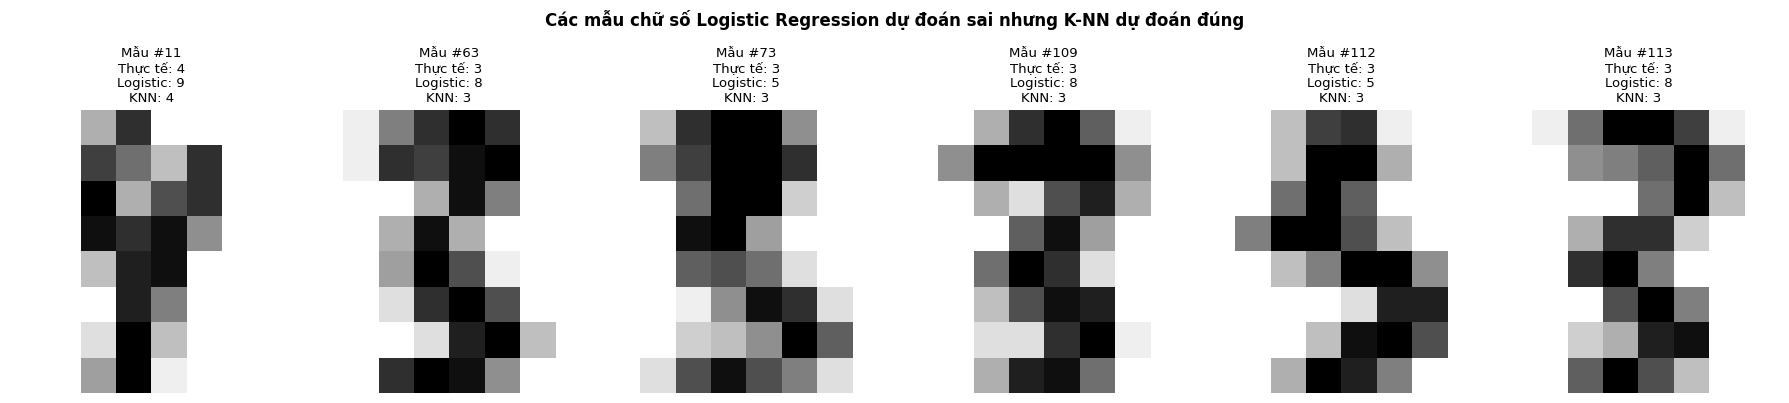

In [4]:
# ==============================================================================
# BƯỚC 3: TRÍCH XUẤT VÀ VẼ HÌNH ẢNH CÁC MẪU DỰ ĐOÁN ĐỐI LẬP GIỮA HAI MÔ HÌNH
# ==============================================================================

# Nạp cấu trúc ma trận hình ảnh 8x8 gốc từ tập dữ liệu Digits
digits_raw = datasets.load_digits()

# Cắt lấy 10% hình ảnh gốc cuối cùng tương ứng với tập Test (180 ảnh kích thước 8x8)
test_images = digits_raw.images[int(0.9 * n_samples):]

# ------------------------------------------------------------------------------
# 3.1. Tìm chỉ số các mẫu: K-NN đoán sai nhưng Logistic Regression đoán đúng
# ------------------------------------------------------------------------------
knn_wrong_log_right = np.where((y_pred_knn != y_test) & (y_pred_logistic == y_test))[0]

# ------------------------------------------------------------------------------
# 3.2. Tìm chỉ số các mẫu: Logistic Regression đoán sai nhưng K-NN đoán đúng
# ------------------------------------------------------------------------------
log_wrong_knn_right = np.where((y_pred_logistic != y_test) & (y_pred_knn == y_test))[0]

# In ra số lượng mẫu tìm được
print(f"Số mẫu KNN đoán sai nhưng Logistic đoán đúng: {len(knn_wrong_log_right)} mẫu (Chỉ số index: {list(knn_wrong_log_right)})")
print(f"Số mẫu Logistic đoán sai nhưng KNN đoán đúng: {len(log_wrong_knn_right)} mẫu (Chỉ số index: {list(log_wrong_knn_right)})")

# ------------------------------------------------------------------------------
# VẼ HÌNH ẢNH TRƯỜNG HỢP: KNN ĐOÁN SAI - LOGISTIC REGRESSION ĐOÁN ĐÚNG (1 MẪU)
# ------------------------------------------------------------------------------
plt.figure(figsize=(4.5, 4.5))
idx_c1 = knn_wrong_log_right[0]
plt.imshow(test_images[idx_c1], cmap='gray_r', interpolation='nearest')
plt.title(
    f"Mẫu #{idx_c1}\n"
    f"Nhãn thực tế: {y_test[idx_c1]}\n"
    f"KNN dự đoán: {y_pred_knn[idx_c1]}\n"
    f"Logistic dự đoán: {y_pred_logistic[idx_c1]}",
    fontsize=11
)
plt.axis('off')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# VẼ HÌNH ẢNH TRƯỜNG HỢP: LOGISTIC REGRESSION ĐOÁN SAI - KNN ĐOÁN ĐÚNG (6 MẪU)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(nrows=1, ncols=len(log_wrong_knn_right), figsize=(18, 4))
for i, idx in enumerate(log_wrong_knn_right):
    axes[i].imshow(test_images[idx], cmap='gray_r', interpolation='nearest')
    axes[i].set_title(
        f"Mẫu #{idx}\n"
        f"Thực tế: {y_test[idx]}\n"
        f"Logistic: {y_pred_logistic[idx]}\n"
        f"KNN: {y_pred_knn[idx]}",
        fontsize=9.5
    )
    axes[i].axis('off')

plt.suptitle("Các mẫu chữ số Logistic Regression dự đoán sai nhưng K-NN dự đoán đúng", fontsize=12, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


## 4. Trực quan hóa các mẫu nhận dạng sai của cả 2 mô hình


Tổng số mẫu mà cả 2 mô hình đều dự đoán sai: 6 mẫu (Chỉ số index: [np.int64(41), np.int64(43), np.int64(45), np.int64(49), np.int64(110), np.int64(148)])


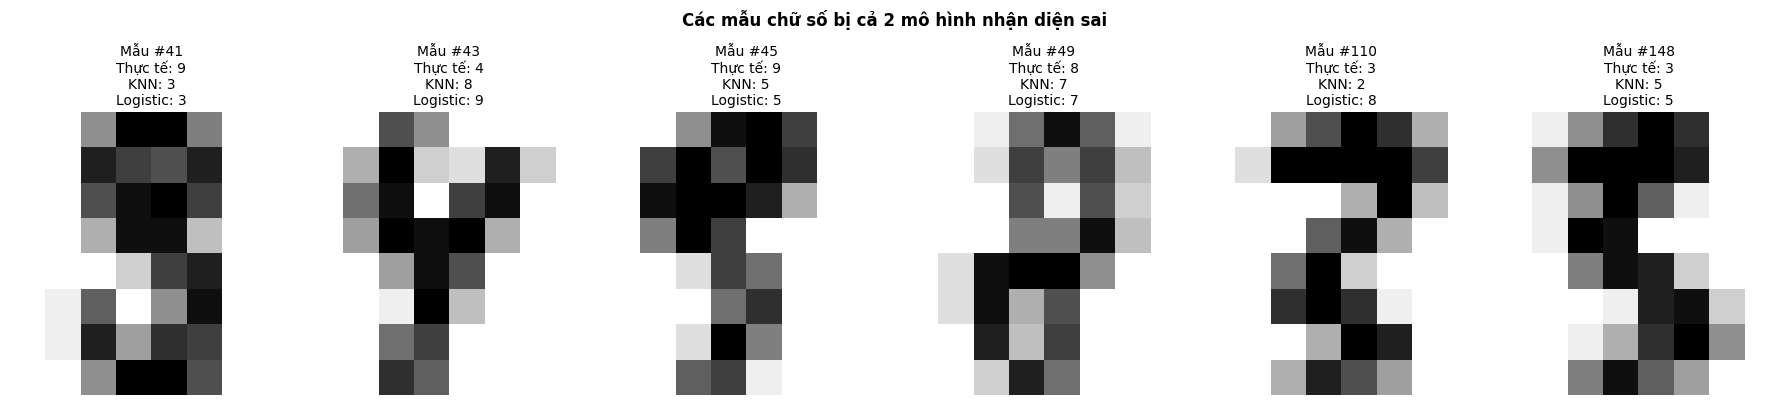


=== BẢNG CHI TIẾT CÁC MẪU CẢ 2 MÔ HÌNH ĐỀU DỰ ĐOÁN SAI ===
Mẫu index #41  | Nhãn thực tế: 9 | KNN dự đoán: 3 | Logistic dự đoán: 3
Mẫu index #43  | Nhãn thực tế: 4 | KNN dự đoán: 8 | Logistic dự đoán: 9
Mẫu index #45  | Nhãn thực tế: 9 | KNN dự đoán: 5 | Logistic dự đoán: 5
Mẫu index #49  | Nhãn thực tế: 8 | KNN dự đoán: 7 | Logistic dự đoán: 7
Mẫu index #110 | Nhãn thực tế: 3 | KNN dự đoán: 2 | Logistic dự đoán: 8
Mẫu index #148 | Nhãn thực tế: 3 | KNN dự đoán: 5 | Logistic dự đoán: 5


In [5]:
# ==============================================================================
# BƯỚC 4: TRÍCH XUẤT VÀ VẼ HÌNH ẢNH CÁC MẪU MÀ CẢ 2 MÔ HÌNH ĐỀU NHẬN DIỆN SAI
# ==============================================================================

# Tìm các chỉ số mẫu mà cả mô hình K-NN VÀ mô hình Logistic Regression đều nhận diện sai
both_wrong = np.where((y_pred_knn != y_test) & (y_pred_logistic != y_test))[0]

print(f"Tổng số mẫu mà cả 2 mô hình đều dự đoán sai: {len(both_wrong)} mẫu (Chỉ số index: {list(both_wrong)})")

# Khởi tạo khung hình chứa 6 ô ảnh con nằm ngang
fig, axes = plt.subplots(nrows=1, ncols=len(both_wrong), figsize=(18, 4))

for i, idx in enumerate(both_wrong):
    axes[i].imshow(test_images[idx], cmap='gray_r', interpolation='nearest')
    axes[i].set_title(
        f"Mẫu #{idx}\n"
        f"Thực tế: {y_test[idx]}\n"
        f"KNN: {y_pred_knn[idx]}\n"
        f"Logistic: {y_pred_logistic[idx]}",
        fontsize=10
    )
    axes[i].axis('off')

plt.suptitle("Các mẫu chữ số bị cả 2 mô hình nhận diện sai", fontsize=12, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# IN BẢNG THỐNG KÊ CHI TIẾT TỪNG MẪU SAI CHUNG
# ------------------------------------------------------------------------------
print("\n=== BẢNG CHI TIẾT CÁC MẪU CẢ 2 MÔ HÌNH ĐỀU DỰ ĐOÁN SAI ===")
for idx in both_wrong:
    print(
        f"Mẫu index #{idx:<3} | Nhãn thực tế: {y_test[idx]} | "
        f"KNN dự đoán: {y_pred_knn[idx]} | Logistic dự đoán: {y_pred_logistic[idx]}"
    )
